# Etapa 3: otimização e IA responsável

A Etapa 2 escolheu a regressão logística, com acerto geral (F1 macro) de 0,5822 na validação, praticamente empatada com o
LightGBM sem ajustes (0,5820). Ela deixou dois pontos abertos: os dias Alto avisados ficaram abaixo de 60 de cada 100, e o
modelo perdia para a persistência (a régua "o risco de hoje é o de ontem") nos municípios menores.

Esta etapa otimiza o **LightGBM**, que o enunciado sugere para a otimização e que tem muito mais ajustes para testar do que a
regressão logística. Esta etapa:

1. ajusta o LightGBM com o **Optuna**, ferramenta que testa combinações de ajustes (os hiperparâmetros) e usa o
   resultado de cada tentativa para escolher a próxima;
2. escolhe o **modelo final**, entre o LightGBM otimizado e a regressão logística da Etapa 2;
3. testa um **corte do Alto** (a probabilidade a partir da qual o dia vira Alto) **para cada faixa de tamanho** de município;
4. explica as decisões do modelo final com o **SHAP**, método que mostra quanto cada coluna pesou em cada previsão;
5. procura **viés** (o modelo errar mais para um grupo) por região, bioma e distância até a estação meteorológica;
6. gera um **boletim em texto** por município, com regra fixa;
7. responde à hipótese do projeto.

**Cada período tem um papel só.** Os ajustes do Optuna são escolhidos em julho, agosto e setembro, dentro do treino.
Outubro (a validação) serve só para escolher os cortes e para as duas escolhas finais: o modelo e o tipo de corte. O
teste (novembro de 2024 a fevereiro de 2025) mede o resultado. O critério das escolhas é o mesmo da Etapa 2, fixado
antes: o maior acerto geral (F1 macro). As métricas são as da seção 2 do `02_modelagem.ipynb`.

In [1]:
import json
import sys
import time
import warnings
from pathlib import Path

warnings.filterwarnings('ignore', message='IProgress not found')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
import lightgbm as lgb
import optuna
import shap
from sklearn.metrics import f1_score

RAIZ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'src' / 'consolidar_base.py').exists())
sys.path.insert(0, str(RAIZ / 'src'))
import preparar_modelagem as pm

RESULTADOS = RAIZ / 'resultados' / 'etapa3'
RESULTADOS.mkdir(parents=True, exist_ok=True)
AZUL, CINZA, LARANJA, VERMELHO = '#2f6fdb', '#9aa5b1', '#e8a33d', '#c0392b'
SEMENTE = 12345
optuna.logging.set_verbosity(optuna.logging.WARNING)

base = pm.carregar_base()
treino, validacao, teste = pm.dividir_por_tempo(base)
amostra = treino.sample(400_000, random_state=SEMENTE)
X_am, y_am = amostra[pm.FEATURES], amostra['nivel_risco'].astype(str)
X_va, y_va = validacao[pm.FEATURES], validacao['nivel_risco'].astype(str)
X_te, y_te = teste[pm.FEATURES], teste['nivel_risco'].astype(str)
persistencia_te = pm.persistencia(teste).values

COMUM = dict(class_weight='balanced', random_state=SEMENTE, verbose=-1, deterministic=True, force_row_wise=True)
AJUSTES_ETAPA2 = dict(n_estimators=400, learning_rate=0.05, num_leaves=63)

print(f'treino {len(treino):,} | amostra {len(amostra):,} | validação {len(validacao):,} | teste {len(teste):,}'.replace(',', ' '))

treino 1 355 812 | amostra 400 000 | validação 172 316 | teste 578 283


## 1. Otimização com o Optuna

**O que é ajustado:** o número de árvores, a velocidade de aprendizado, o tamanho das árvores, o mínimo de linhas
em cada folha (a ponta da árvore, onde sai a resposta), a fração de linhas e de colunas usada em cada árvore e a
força da regularização (um freio que evita decorar o treino).

**Como cada tentativa é avaliada, sem tocar em outubro:** três **dobras cronológicas** dentro do treino. Em cada uma, o
modelo aprende com os meses anteriores e é avaliado no mês seguinte: aprende até junho e é avaliado em julho; aprende até
julho e é avaliado em agosto; aprende até agosto e é avaliado em setembro. A nota da tentativa é a média dos três acertos
gerais (F1 macro), com as notas de corte escolhidas em cada mês. São **30 tentativas**. A mesma conta é feita para o
LightGBM sem ajustes, como referência.

In [2]:
GRADE_ALTO = np.round(np.arange(0.20, 0.76, 0.05), 2)
GRADE_MEDIO = (0.40, 0.45, 0.50, 0.55, 0.60)

def melhores_cortes(y, prob):
    # Grade mais curta que a da Etapa 2, para caber em cada tentativa do Optuna.
    return pm.escolher_cortes(y, prob, GRADE_ALTO, GRADE_MEDIO)

# Três dobras cronológicas dentro do treino: aprende com os meses anteriores e é avaliada no mês seguinte.
# Outubro (a validação) fica de fora do Optuna.
DOBRAS = []
for mes in ['2024-07', '2024-08', '2024-09']:
    antes = treino[treino['dia'] < pd.Timestamp(f'{mes}-01')]
    amostra_dobra = antes.sample(min(400_000, len(antes)), random_state=SEMENTE)
    do_mes = treino[treino['dia'].dt.to_period('M') == pd.Period(mes)]
    DOBRAS.append((amostra_dobra[pm.FEATURES], amostra_dobra['nivel_risco'].astype(str),
                   do_mes[pm.FEATURES], do_mes['nivel_risco'].astype(str)))

def nota_nas_dobras(ajustes):
    notas = []
    for X_dobra, y_dobra, X_mes, y_mes in DOBRAS:
        modelo_dobra = lgb.LGBMClassifier(**ajustes, **COMUM).fit(X_dobra, y_dobra)
        notas.append(melhores_cortes(y_mes, pm.probabilidades(modelo_dobra, X_mes))[2])
    return float(np.mean(notas))

def tentativa(trial):
    return nota_nas_dobras(dict(n_estimators=trial.suggest_int('n_estimators', 150, 700, step=50),
                                learning_rate=trial.suggest_float('learning_rate', 0.01, 0.15, log=True),
                                num_leaves=trial.suggest_int('num_leaves', 15, 127),
                                min_child_samples=trial.suggest_int('min_child_samples', 20, 400),
                                subsample=trial.suggest_float('subsample', 0.6, 1.0),
                                colsample_bytree=trial.suggest_float('colsample_bytree', 0.5, 1.0),
                                reg_lambda=trial.suggest_float('reg_lambda', 1e-2, 50, log=True),
                                subsample_freq=1))

inicio = time.time()
nota_sem_ajustes = nota_nas_dobras(AJUSTES_ETAPA2)
estudo = optuna.create_study(direction='maximize', sampler=optuna.samplers.TPESampler(seed=SEMENTE))
estudo.optimize(tentativa, n_trials=30)
print(f'{time.time() - inicio:.0f} s | F1 macro médio nas 3 dobras: sem ajustes {nota_sem_ajustes:.4f} | melhor {estudo.best_value:.4f}'.replace('.', ','))
(RESULTADOS / 'melhores_ajustes.json').write_text(json.dumps(estudo.best_params, indent=1))
pd.Series(estudo.best_params).round(4).to_frame('valor')

1675 s | F1 macro médio nas 3 dobras: sem ajustes 0,5713 | melhor 0,5731


,valor
n_estimators,200.0000
learning_rate,0.0154
num_leaves,75.0000
min_child_samples,383.0000
subsample,0.8058
colsample_bytree,0.8095
reg_lambda,0.5554


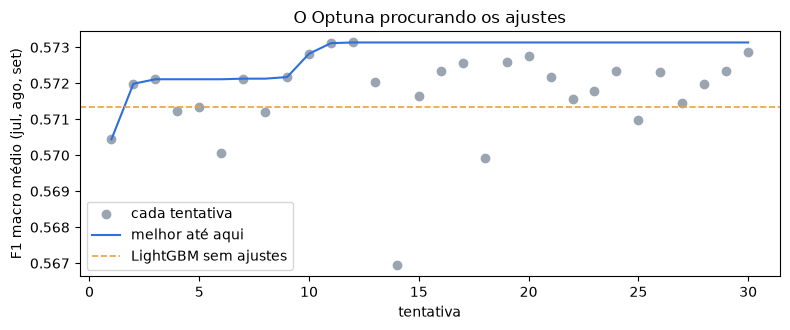

In [3]:
historico = pd.Series([t.value for t in estudo.trials], index=range(1, len(estudo.trials) + 1))
fig, eixo = plt.subplots(figsize=(8, 3.4))
eixo.scatter(historico.index, historico.values, color=CINZA, label='cada tentativa')
eixo.plot(historico.index, historico.cummax(), color=AZUL, label='melhor até aqui')
eixo.axhline(nota_sem_ajustes, color=LARANJA, linestyle='--', linewidth=1.2, label='LightGBM sem ajustes')
eixo.set_xlabel('tentativa')
eixo.set_ylabel('F1 macro médio (jul, ago, set)')
eixo.set_title('O Optuna procurando os ajustes')
eixo.legend()
plt.tight_layout()
plt.show()

**O ganho do Optuna é pequeno:** o acerto geral médio nas três dobras sobe de 0,5713 (LightGBM sem ajustes) para 0,5731.
Os ajustes vencedores usam menos árvores (200 contra 400), maiores (75 folhas contra 63) e com aprendizado mais lento
(taxa de 0,015 contra 0,05). O ganho modesto é comum: o que mais limita o resultado é a informação disponível na véspera,
e não os ajustes do modelo.

## 2. As escolhas finais, em outubro

Agora outubro entra pela primeira vez na Etapa 3, para duas escolhas, ambas pelo critério fixado antes: o maior acerto
geral (F1 macro) em outubro.

**O modelo final.** O LightGBM otimizado e a regressão logística da Etapa 2 recebem, cada um, as notas de corte escolhidas
em outubro, com a mesma grade, e o maior acerto geral vira o modelo final.

**Corte único ou um corte para cada tamanho de município.** A Etapa 2 viu, na validação, que o modelo perde para a
persistência nos municípios menores: eles quase não têm dias Alto, e o modelo dá a eles probabilidades mais baixas, que
um corte único quase nunca avisa. A alternativa é dividir os municípios em cinco faixas de área (com os limites
calculados no treino) e escolher, em outubro, o corte do Alto de cada faixa, pelo maior F1 do Alto. Ela só é adotada se
o acerto geral em outubro for maior que o do corte único.

In [4]:
modelo_etapa2 = lgb.LGBMClassifier(**AJUSTES_ETAPA2, **COMUM).fit(X_am, y_am)
prob_va_e2, prob_te_e2 = pm.probabilidades(modelo_etapa2, X_va), pm.probabilidades(modelo_etapa2, X_te)
corte_alto_e2, corte_medio_e2, _ = pm.escolher_cortes(y_va, prob_va_e2)

# Escolha 1, em outubro: o LightGBM otimizado contra a regressão logística da Etapa 2, pelo F1 macro,
# cada um com as próprias notas de corte, escolhidas em outubro com a mesma grade.
candidatos = {'LightGBM otimizado': lgb.LGBMClassifier(**estudo.best_params, subsample_freq=1, **COMUM).fit(X_am, y_am),
              'Regressão logística': pm.montar_modelos(pm.FEATURES_NUMERICAS, SEMENTE)['Regressão logística'].fit(X_am, y_am)}
prob_cand, cortes_cand = {}, {}
for nome, candidato in candidatos.items():
    prob_cand[nome] = pm.probabilidades(candidato, X_va), pm.probabilidades(candidato, X_te)
    cortes_cand[nome] = pm.escolher_cortes(y_va, prob_cand[nome][0])
escolha_modelo = pd.DataFrame({nome: {'corte do Alto': c[0], 'corte do Médio': c[1], 'F1 macro em outubro': round(c[2], 4)}
                               for nome, c in cortes_cand.items()}).T
escolha_modelo.to_csv(RESULTADOS / 'escolha_do_modelo_outubro.csv')
NOME_FINAL = max(cortes_cand, key=lambda nome: cortes_cand[nome][2])
print(escolha_modelo)
print('Modelo final:', NOME_FINAL, '\n')

modelo = candidatos[NOME_FINAL]
prob_va, prob_te = prob_cand[NOME_FINAL]
corte_alto, corte_medio, _ = cortes_cand[NOME_FINAL]

municipios_treino = treino.drop_duplicates('id_municipio')['area_km2']
LIMITES_AREA = np.quantile(municipios_treino, [.2, .4, .6, .8])
NOMES_FAIXA = ['1 (menores)', '2', '3', '4', '5 (maiores)']
faixa_va, faixa_te = np.digitize(validacao['area_km2'], LIMITES_AREA), np.digitize(teste['area_km2'], LIMITES_AREA)

y_va_np, y_te_np = y_va.values, y_te.values
cortes_faixa = {}
for faixa in range(5):
    dentro = faixa_va == faixa
    notas = {c: f1_score(y_va_np[dentro] == 'Alto', pm.decidir(prob_va[dentro], c, corte_medio) == 'Alto')
             for c in np.round(np.arange(0.05, 0.91, 0.05), 2)}
    cortes_faixa[faixa] = max(notas, key=notas.get)

def decidir_por_faixa(prob, faixas):
    cortes = np.array([cortes_faixa[f] for f in faixas])
    return np.where(prob[:, 2] >= cortes, 'Alto', np.where(prob[:, 1] >= corte_medio, 'Médio', 'Baixo'))

prev_unico_va, prev_unico_te = pm.decidir(prob_va, corte_alto, corte_medio), pm.decidir(prob_te, corte_alto, corte_medio)
prev_faixa_va, prev_faixa_te = decidir_por_faixa(prob_va, faixa_va), decidir_por_faixa(prob_te, faixa_te)

# Escolha 2, em outubro: corte único ou por faixa, pelo F1 macro (o mesmo critério de todo o projeto).
f1_unico_out, f1_faixa_out = pm.metricas(y_va, prev_unico_va)['f1_macro'], pm.metricas(y_va, prev_faixa_va)['f1_macro']
ESCOLHA_CORTE = 'corte por faixa' if f1_faixa_out > f1_unico_out else 'corte único'
prev_final_va, prev_final_te = (prev_faixa_va, prev_faixa_te) if ESCOLHA_CORTE == 'corte por faixa' else (prev_unico_va, prev_unico_te)
cortes_finais = [float(cortes_faixa[f]) for f in range(5)] if ESCOLHA_CORTE == 'corte por faixa' else [float(corte_alto)] * 5

print(f'Corte único: {corte_alto:.2f} | corte do Médio: {corte_medio:.2f}'.replace('.', ','))
print('Corte por faixa:', ' | '.join(f'{NOMES_FAIXA[f]}: {c:.2f}'.replace('.', ',') for f, c in cortes_faixa.items()))
print(f'F1 macro em outubro: corte único {f1_unico_out:.4f} | corte por faixa {f1_faixa_out:.4f} -> {ESCOLHA_CORTE}'.replace('.', ','))

# Guarda o modelo final e as regras de decisão, para reuso sem treinar de novo.
joblib.dump(modelo, RESULTADOS / 'modelo_final.joblib')
(RESULTADOS / 'cortes_finais.json').write_text(json.dumps(
    {'modelo': NOME_FINAL, 'corte': ESCOLHA_CORTE, 'limites_area_km2': [round(float(l), 2) for l in LIMITES_AREA], 'corte_alto_por_faixa': cortes_finais,
     'corte_medio': float(corte_medio)}, indent=1))
na_validacao = pd.DataFrame({'corte único': pm.metricas(y_va, prev_unico_va),
                             'corte por faixa': pm.metricas(y_va, prev_faixa_va)}).T[['f1_macro', 'precisao_alto', 'recall_alto', 'f1_alto']].round(4)
na_validacao.to_csv(RESULTADOS / 'cortes_na_validacao.csv')

# A mesma análise por tamanho, feita em outubro.
faixas_outubro = []
for faixa in range(5):
    dentro = faixa_va == faixa
    faixas_outubro.append({'faixa de área': NOMES_FAIXA[faixa], '% dias Alto': round((y_va_np[dentro] == 'Alto').mean() * 100, 2),
                           'F1 Alto, corte único': pm.metricas(y_va_np[dentro], prev_unico_va[dentro])['f1_alto'],
                           'F1 Alto, corte por faixa': pm.metricas(y_va_np[dentro], prev_faixa_va[dentro])['f1_alto'],
                           'F1 Alto, persistência': pm.metricas(y_va_np[dentro], pm.persistencia(validacao[dentro]).values)['f1_alto']})
faixas_outubro = pd.DataFrame(faixas_outubro).set_index('faixa de área').round(4)
faixas_outubro.to_csv(RESULTADOS / 'por_tamanho_validacao.csv')
print(faixas_outubro)
na_validacao

                     corte do Alto  corte do Médio  F1 macro em outubro
LightGBM otimizado            0.55             0.5               0.5817
Regressão logística           0.55             0.5               0.5822
Modelo final: Regressão logística 



Corte único: 0,55 | corte do Médio: 0,50
Corte por faixa: 1 (menores): 0,40 | 2: 0,45 | 3: 0,45 | 4: 0,50 | 5 (maiores): 0,60
F1 macro em outubro: corte único 0,5822 | corte por faixa 0,5772 -> corte único


               % dias Alto  F1 Alto, corte único  F1 Alto, corte por faixa  \
faixa de área                                                                
1 (menores)           1.27                0.1621                    0.2257   
2                     2.50                0.2675                    0.2822   
3                     5.66                0.3397                    0.3599   
4                    13.78                0.5230                    0.5298   
5 (maiores)          38.92                0.7345                    0.7357   

               F1 Alto, persistência  
faixa de área                         
1 (menores)                   0.1998  
2                             0.2653  
3                             0.3227  
4                             0.4935  
5 (maiores)                   0.7169  


,f1_macro,precisao_alto,recall_alto,f1_alto
corte único,0.5822,0.6083,0.6737,0.6393
corte por faixa,0.5772,0.5833,0.6778,0.6270


In [5]:
opcoes = {'Persistência': (persistencia_te, None),
          'LightGBM sem ajustes': (pm.decidir(prob_te_e2, corte_alto_e2, corte_medio_e2), prob_te_e2)}
for nome in candidatos:
    opcoes[nome] = (pm.decidir(prob_cand[nome][1], *cortes_cand[nome][:2]), prob_cand[nome][1])
opcoes[f'{NOME_FINAL}, corte por faixa'] = (prev_faixa_te, prob_te)
comparacao = pd.DataFrame({nome: pm.metricas(y_te, previsto, prob) for nome, (previsto, prob) in opcoes.items()}).T[
    ['acuracia', 'f1_macro', 'precisao_alto', 'recall_alto', 'f1_alto', 'f1_medio', 'auc_roc']].round(4)
custos = [pm.custo_total(y_te_np, previsto) for previsto, _ in opcoes.values()]
comparacao['custo (R$ milhões)'] = [round(total / 1e6, 1) for total, _, _ in custos]
comparacao['avisos Alto'] = [avisos for _, avisos, _ in custos]
comparacao['dias Alto sem aviso'] = [perdidos for _, _, perdidos in custos]
comparacao.to_csv(RESULTADOS / 'comparacao_teste.csv')
comparacao

,acuracia,f1_macro,precisao_alto,recall_alto,f1_alto,f1_medio,auc_roc,custo (R$ milhões),avisos Alto,dias Alto sem aviso
Persistência,0.8423,0.5490,0.4921,0.4982,0.4951,0.2295,NaN,434.8,30961,15347
LightGBM sem ajustes,0.7790,0.5651,0.5730,0.5075,0.5382,0.2779,0.8590,423.4,27087,15063
LightGBM otimizado,0.7799,0.5667,0.5774,0.5228,0.5488,0.2723,0.8587,411.7,27691,14594
Regressão logística,0.8085,0.5709,0.5757,0.5116,0.5418,0.2718,0.8581,420.1,27179,14936
"Regressão logística, corte por faixa",0.8078,0.5694,0.5541,0.5220,0.5375,0.2716,0.8581,413.5,28809,14620


In [6]:
sensibilidade = pm.sensibilidade_economia(y_te_np, prev_final_te, persistencia_te)
sensibilidade.to_csv(RESULTADOS / 'sensibilidade_economia.csv')
print('Economia do modelo final contra a persistência, em R$ milhões, no período de teste:')
sensibilidade

Economia do modelo final contra a persistência, em R$ milhões, no período de teste:


,equipe R$ 500,equipe R$ 1.032,equipe R$ 2.000
área a mais queimada sem equipe,,,
1 ha,4.0,6.1,9.7
2 ha,6.2,8.2,11.9
5 ha,12.7,14.7,18.4
10 ha,23.5,25.5,29.1
20 ha,45.0,47.1,50.7


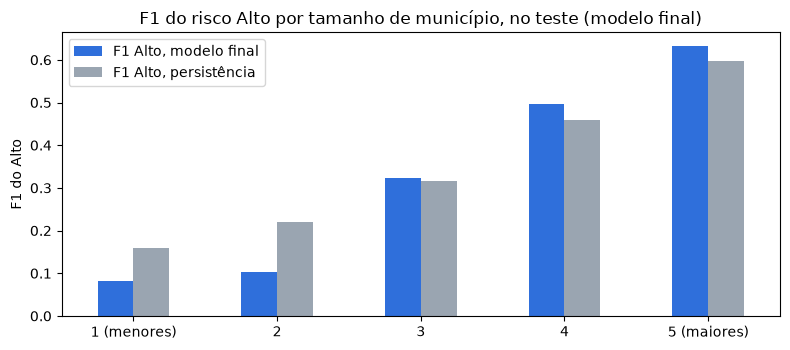

,% dias Alto,"F1 Alto, modelo final","F1 Alto, persistência"
faixa de área,,,
1 (menores),0.76,0.0823,0.1590
2,1.57,0.1021,0.2212
3,3.03,0.3240,0.3155
4,6.60,0.4975,0.4583
5 (maiores),14.48,0.6328,0.5966


In [7]:
por_tamanho = []
for faixa in range(5):
    dentro = faixa_te == faixa
    por_tamanho.append({'faixa de área': NOMES_FAIXA[faixa], '% dias Alto': round((y_te_np[dentro] == 'Alto').mean() * 100, 2),
                        'F1 Alto, modelo final': pm.metricas(y_te_np[dentro], prev_final_te[dentro])['f1_alto'],
                        'F1 Alto, persistência': pm.metricas(y_te_np[dentro], persistencia_te[dentro])['f1_alto']})
por_tamanho = pd.DataFrame(por_tamanho).set_index('faixa de área').round(4)
por_tamanho.to_csv(RESULTADOS / 'por_tamanho_de_municipio.csv')

fig, eixo = plt.subplots(figsize=(8, 3.6))
por_tamanho[['F1 Alto, modelo final', 'F1 Alto, persistência']].plot(kind='bar', rot=0, color=[AZUL, CINZA], ax=eixo)
eixo.set_title('F1 do risco Alto por tamanho de município, no teste (modelo final)')
eixo.set_ylabel('F1 do Alto')
eixo.set_xlabel('')
plt.tight_layout()
plt.show()
por_tamanho

**A regressão logística é o modelo final.** Em outubro, ela tem acerto geral de 0,5822, contra 0,5817 do LightGBM
otimizado. A diferença é mínima, e a regra decide. Com os ajustes escolhidos sem olhar outubro, a otimização não superou o
modelo mais simples.

**O corte por faixa não foi adotado.** Em outubro, ele melhora o F1 do Alto em todas as faixas, sobretudo nas menores
(0,2257 contra 0,1621 na faixa 1), mas o acerto geral cai (0,5772 contra 0,5822), porque ele avisa mais dias com menos
acerto nos níveis Médio e Baixo. Pelo critério fixado antes, fica o corte único.

**A tabela do teste mostra as alternativas, só para registro.** No teste, o LightGBM otimizado teria ido um pouco melhor
que a regressão logística (custo de R$ 411,7 milhões, contra R$ 420,1 milhões), e o corte por faixa também (R$ 413,5
milhões). Essas diferenças são pequenas e não mudam a escolha, que foi feita em outubro, antes de olhar o teste.

**Em reais:** o modelo final custa R$ 420,1 milhões no período de teste, contra R$ 434,8 milhões da persistência:
**R$ 14,7 milhões a menos (3,4%)**, com as mesmas premissas da Etapa 2, incluindo os 5 hectares, que não têm fonte
publicada. A economia é positiva em 15 dos 15 cenários, de R$ 4,0 a R$ 50,7 milhões.

**Por tamanho de município, no teste:** o modelo final supera a persistência nas 3 faixas maiores e perde nas 2 menores. Na
validação, a perda aparecia só na faixa dos menores.

## 3. Dá para atingir as duas metas do Alto ao mesmo tempo?

Baixar o corte faz o modelo avisar mais dias, mas com menos avisos certos. Subir o corte faz o contrário. A curva
abaixo mostra essa troca e onde ficam as metas (60 dias avisados e 55 avisos certos, de cada 100). Ela serve só para
enxergar o limite do modelo: **o corte final não é escolhido aqui**, porque esta curva olha o teste.

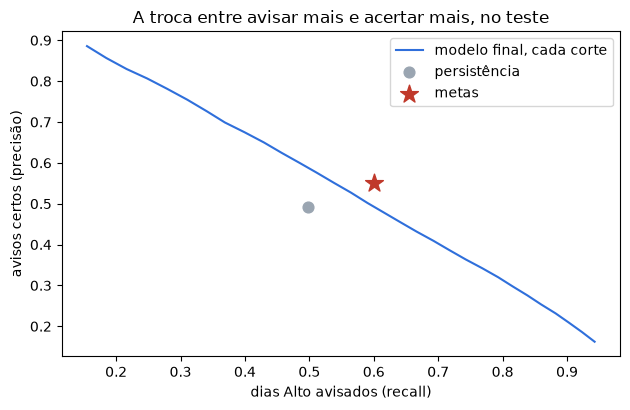

 corte  recall  precisao
  0.45  0.6164    0.4777


In [8]:
curva = []
for corte in np.round(np.arange(0.10, 0.86, 0.025), 3):
    m = pm.metricas(y_te, pm.decidir(prob_te, corte, corte_medio))
    curva.append({'corte': corte, 'recall': m['recall_alto'], 'precisao': m['precisao_alto']})
curva = pd.DataFrame(curva)
curva.to_csv(RESULTADOS / 'troca_recall_precisao_teste.csv', index=False)

fig, eixo = plt.subplots(figsize=(6.4, 4.2))
eixo.plot(curva['recall'], curva['precisao'], color=AZUL, label='modelo final, cada corte')
m_p = comparacao.loc['Persistência']
eixo.scatter([m_p['recall_alto']], [m_p['precisao_alto']], color=CINZA, s=60, zorder=3, label='persistência')
eixo.scatter([0.60], [0.55], color=VERMELHO, marker='*', s=180, zorder=3, label='metas')
eixo.set_xlabel('dias Alto avisados (recall)')
eixo.set_ylabel('avisos certos (precisão)')
eixo.set_title('A troca entre avisar mais e acertar mais, no teste')
eixo.legend()
plt.tight_layout()
plt.show()
perto = curva[(curva['recall'] >= 0.60)].sort_values('precisao', ascending=False).head(1)
print(perto.round(4).to_string(index=False))

In [9]:
mes_a_mes = []
for nome_parte, parte, y_parte, previsto in [('validação', validacao, y_va_np, prev_final_va), ('teste', teste, y_te_np, prev_final_te)]:
    for mes, indices in parte.groupby(parte['dia'].dt.to_period('M')).indices.items():
        m = pm.metricas(y_parte[indices], previsto[indices])
        r = pm.metricas(y_parte[indices], pm.persistencia(parte.iloc[indices]).values)
        mes_a_mes.append({'mês': str(mes), 'parte': nome_parte, '% dias Alto': round((y_parte[indices] == 'Alto').mean() * 100, 2),
                          'recall modelo': m['recall_alto'], 'precisão modelo': m['precisao_alto'], 'F1 Alto modelo': m['f1_alto'],
                          'F1 Alto persistência': r['f1_alto']})
mes_a_mes = pd.DataFrame(mes_a_mes).set_index('mês').round(4)
mes_a_mes.to_csv(RESULTADOS / 'mes_a_mes.csv')
mes_a_mes

,parte,% dias Alto,recall modelo,precisão modelo,F1 Alto modelo,F1 Alto persistência
mês,,,,,,
2024-10,validação,12.41,0.6737,0.6083,0.6393,0.6024
2024-11,teste,8.85,0.6044,0.6172,0.6107,0.5639
2024-12,teste,6.47,0.4980,0.5546,0.5248,0.4900
2025-01,teste,2.14,0.2738,0.4389,0.3372,0.3035
2025-02,teste,1.46,0.1636,0.3945,0.2313,0.2499


**Nenhum corte atinge as duas metas no período de teste.** A estrela fica fora da curva: para avisar 60 de cada 100
dias Alto, o corte precisa cair a 0,45, e a precisão vai a 47,8 de cada 100. As metas foram fixadas na Etapa 1, antes da
modelagem, e não foram mudadas depois.

**O resultado depende muito da época do ano.** O modelo final atinge as duas metas em **outubro e novembro**: em outubro,
67,4 dias Alto avisados e 60,8 avisos certos, de cada 100; em novembro, 60,4 dias Alto avisados e 61,7 avisos certos. A
nota cai em janeiro e fevereiro, com a chuva, quando há poucos dias Alto (cerca de 2%). Na prática, isso é o menos grave
dos cenários: o modelo é mais forte quando há mais fogo, e é aí que as equipes fazem falta. Outubro merece um cuidado:
ele foi usado para escolher os cortes e o modelo, então a nota dele é um pouco otimista.

## 4. Explicabilidade com o SHAP

O SHAP divide cada previsão entre as colunas: para um município-dia (um município num dia), diz quanto cada coluna empurrou o modelo a
favor ou contra o risco Alto. Somando os tamanhos desses empurrões em muitas previsões, sabemos quais colunas mais
pesam. A conta usa 5 000 município-dias sorteados do teste.

Como o modelo final é uma regressão logística, o SHAP sai direto dos pesos do modelo. O preparo cria colunas novas (o
estado vira colunas de 0 e 1, e cada vazio ganha uma coluna de aviso); elas são somadas de volta à coluna original, para
o resultado falar das colunas da base.

In [10]:
amostra_shap = teste.sample(5_000, random_state=SEMENTE)
classes = list(modelo.classes_)
denso = lambda m: m.toarray() if hasattr(m, 'toarray') else m

if NOME_FINAL == 'LightGBM otimizado':
    explicador = shap.TreeExplainer(modelo)
    def valores_shap(X):
        return explicador.shap_values(X[pm.FEATURES])  # linhas × colunas × níveis
else:
    preparo, linear = modelo.named_steps['preparo'], modelo.named_steps['modelo']
    explicador = shap.LinearExplainer(linear, shap.maskers.Independent(denso(preparo.transform(X_am.iloc[:1000])), max_samples=1000))
    # O preparo cria colunas novas (o estado vira colunas de 0 e 1, e cada vazio ganha uma coluna de aviso).
    # Cada uma é somada de volta à coluna original, para o SHAP falar das colunas da base.
    origem = [n.split('__', 1)[1].replace('missingindicator_', '') for n in preparo.get_feature_names_out()]
    origem = ['sigla_uf' if o.startswith('sigla_uf_') else o for o in origem]
    assert set(origem) <= set(pm.FEATURES)
    soma = np.array([[o == f for f in pm.FEATURES] for o in origem], dtype=float)
    def valores_shap(X):
        v = explicador.shap_values(denso(preparo.transform(X[pm.FEATURES])))  # linhas × colunas novas × níveis
        return np.einsum('ntc,tf->nfc', v, soma)

shap_alto = valores_shap(amostra_shap)[:, :, classes.index('Alto')]

peso = pd.Series(np.abs(shap_alto).mean(axis=0), index=pm.FEATURES).sort_values(ascending=False)
peso_tabela = pd.DataFrame({'peso médio': peso.round(4), '% do peso total': (peso / peso.sum() * 100).round(1)})
peso_tabela.to_csv(RESULTADOS / 'peso_das_colunas_shap.csv')
peso_tabela.head(10)

,peso médio,% do peso total
focos_30d,0.3148,20.2
umidade_min_ontem,0.1906,12.2
area_km2,0.1639,10.5
focos_ontem,0.1612,10.3
chuva_ontem,0.1444,9.3
sigla_uf,0.1266,8.1
chuva_7d,0.1185,7.6
focos_7d,0.1125,7.2
dias_com_foco_30d,0.0943,6.0
pct_pastagem,0.0365,2.3


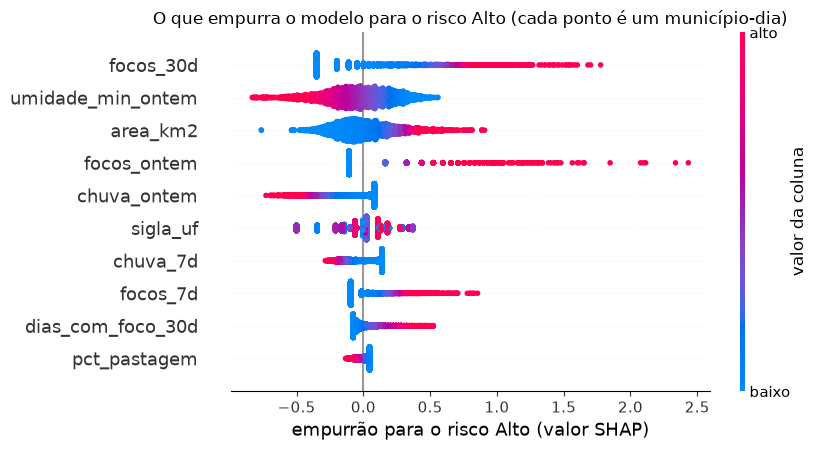

In [11]:
para_grafico = amostra_shap[pm.FEATURES].copy()
para_grafico['sigla_uf'] = para_grafico['sigla_uf'].cat.codes
shap.summary_plot(shap_alto, para_grafico, max_display=10, show=False, plot_size=(8.5, 4.6))
eixos_shap = plt.gcf().axes
eixos_shap[0].set_title('O que empurra o modelo para o risco Alto (cada ponto é um município-dia)')
eixos_shap[0].set_xlabel('empurrão para o risco Alto (valor SHAP)')
eixos_shap[-1].set_ylabel('valor da coluna')
eixos_shap[-1].set_yticklabels(['baixo', 'alto'])
plt.tight_layout()
plt.show()

**Como ler o gráfico:** cada ponto é um município-dia. À direita do zero, a coluna empurrou para o risco Alto; à esquerda,
contra. Vermelho é valor alto da coluna, e azul é valor baixo. Em `umidade_min_ontem`, os pontos vermelhos ficam à
esquerda: umidade alta afasta o risco. Em `focos_30d`, ficam à direita: muitos focos aproximam o risco.

**As 3 colunas que mais pesam no risco Alto:**

| Coluna | Peso | O que quer dizer |
|---|---|---|
| `focos_30d` | 20,2% | focos no município nos últimos 30 dias: lugar que vem queimando tende a seguir queimando |
| `umidade_min_ontem` | 12,2% | umidade mínima de ontem: quanto mais seco o ar, maior o risco |
| `area_km2` | 10,5% | área do município: o alvo conta focos sem dividir pela área, e município maior tem mais área para queimar |

O peso é a parte de cada coluna no total dos empurrões. `focos_ontem` vem colada em quarto lugar (10,3%). Juntas, as
quatro colunas de histórico de focos somam 43,7% do peso, e as de clima da véspera mostradas na tabela (umidade, chuva de
ontem e chuva de 7 dias) somam 29,1%. Isso confirma as duas hipóteses da Etapa 1: o fogo de ontem avisa o de hoje, e o ar
seco acompanha o fogo.

**Um cuidado:** o SHAP mostra no que o modelo se apoia, e não o que causa o fogo. Ele não prova que o ar seco provoca
um incêndio; mostra que o modelo usa essa pista.

## 5. Testes de viés

Viés aqui quer dizer: o modelo trata pior algum grupo? A base não tem pessoas, então não há gênero nem idade. Os
grupos que importam são os lugares, porque é o lugar que deixa de receber equipe. Três recortes:

- **Região do país;**
- **Bioma** (grande tipo de vegetação): cada município recebe o bioma mais frequente nos seus focos. O bioma não
  entra no modelo, e aqui serve só para medir;
- **Distância até a estação meteorológica:** quanto mais longe a estação, menos o clima dela descreve o município.

Para cada grupo, a tabela mostra quantos dias Alto o modelo avisa (recall) e quantos avisos se confirmam (precisão),
comparados com a persistência no mesmo grupo. O número de dias Alto importa: um grupo com poucos dias Alto tem nota
instável. O teste cobre novembro a fevereiro, então grupos cuja seca cai em outra época têm pouco fogo nesse período.

In [12]:
bioma = pd.read_csv(RAIZ / 'dados' / 'processado' / 'bioma_municipio.csv')
grupos = teste[['regiao', 'id_municipio', 'distancia_estacao_km']].copy()
grupos['id_municipio'] = grupos['id_municipio'].astype('int64')
grupos = grupos.merge(bioma, on='id_municipio', how='left')
grupos['bioma'] = grupos['bioma'].fillna('sem foco registrado')
distancia_tipica = grupos.groupby('id_municipio')['distancia_estacao_km'].transform('median')
grupos['estacao'] = np.select([distancia_tipica > 150, distancia_tipica <= 50], ['mais de 150 km', 'até 50 km'], '50 a 150 km')

def por_grupo(coluna):
    linhas = []
    for nome, indices in grupos.groupby(coluna).indices.items():
        y_g = y_te_np[indices]
        m = pm.metricas(y_g, prev_final_te[indices])
        r = pm.metricas(y_g, persistencia_te[indices])
        linhas.append({coluna: nome, 'municípios': grupos['id_municipio'].iloc[indices].nunique(), 'dias Alto': int((y_g == 'Alto').sum()),
                       'recall modelo': m['recall_alto'], 'recall persistência': r['recall_alto'],
                       'precisão modelo': m['precisao_alto'], 'precisão persistência': r['precisao_alto'],
                       'F1 Alto modelo': m['f1_alto'], 'F1 Alto persistência': r['f1_alto']})
    tabela = pd.DataFrame(linhas).set_index(coluna).round(4).sort_values('dias Alto', ascending=False)
    tabela.to_csv(RESULTADOS / f'vies_por_{coluna}.csv')
    return tabela

vies_regiao = por_grupo('regiao')
vies_bioma = por_grupo('bioma')
vies_estacao = por_grupo('estacao')

# A mesma conta em outubro, quando ainda é seco em boa parte do país.
outubro = []
for nome, indices in validacao.groupby('regiao').indices.items():
    y_g = y_va_np[indices]
    m = pm.metricas(y_g, prev_final_va[indices])
    r = pm.metricas(y_g, pm.persistencia(validacao.iloc[indices]).values)
    outubro.append({'regiao': nome, 'dias Alto em outubro': int((y_g == 'Alto').sum()), 'recall modelo em outubro': m['recall_alto'],
                    'F1 Alto modelo em outubro': m['f1_alto'], 'F1 Alto persistência em outubro': r['f1_alto']})
outubro = pd.DataFrame(outubro).set_index('regiao').round(4)
outubro.to_csv(RESULTADOS / 'vies_por_regiao_outubro.csv')
vies_regiao

,municípios,dias Alto,recall modelo,recall persistência,precisão modelo,precisão persistência,F1 Alto modelo,F1 Alto persistência
regiao,,,,,,,,
Nordeste,1793,19418,0.4825,0.4838,0.5739,0.4801,0.5243,0.4819
Norte,444,7583,0.7409,0.6513,0.6101,0.6374,0.6692,0.6443
Centro-Oeste,467,1814,0.2789,0.3330,0.4400,0.3272,0.3414,0.3301
Sudeste,1666,1132,0.0733,0.1625,0.3242,0.1620,0.1196,0.1623
Sul,1191,636,0.1101,0.1808,0.2954,0.1737,0.1604,0.1772


In [13]:
outubro.loc[vies_regiao.index]

,dias Alto em outubro,recall modelo em outubro,F1 Alto modelo em outubro,F1 Alto persistência em outubro
regiao,,,,
Nordeste,9750,0.6336,0.6491,0.6014
Norte,6306,0.8424,0.7512,0.7309
Centro-Oeste,2234,0.7238,0.6002,0.5859
Sudeste,2761,0.4582,0.4180,0.3868
Sul,336,0.1101,0.1623,0.1568


In [14]:
vies_bioma[vies_bioma['dias Alto'] > 0]

,municípios,dias Alto,recall modelo,recall persistência,precisão modelo,precisão persistência,F1 Alto modelo,F1 Alto persistência
bioma,,,,,,,,
Caatinga,1093,10326,0.3960,0.4322,0.5298,0.4296,0.4532,0.4309
Amazônia,488,9891,0.7542,0.6742,0.6426,0.6601,0.6940,0.6671
Cerrado,1107,6986,0.5398,0.4911,0.5408,0.4851,0.5403,0.4881
Mata Atlântica,2685,3014,0.0474,0.1725,0.3326,0.1718,0.0830,0.1722
Pampa,128,198,0.2222,0.2424,0.2750,0.2412,0.2458,0.2418
Pantanal,7,168,0.8333,0.6250,0.4844,0.6140,0.6127,0.6195


In [15]:
vies_estacao

,municípios,dias Alto,recall modelo,recall persistência,precisão modelo,precisão persistência,F1 Alto modelo,F1 Alto persistência
estacao,,,,,,,,
50 a 150 km,1926,16024,0.5633,0.5309,0.5862,0.5240,0.5745,0.5274
até 50 km,3507,12348,0.4289,0.4421,0.5639,0.4380,0.4872,0.4400
mais de 150 km,128,2211,0.5993,0.5744,0.5544,0.5612,0.5760,0.5677


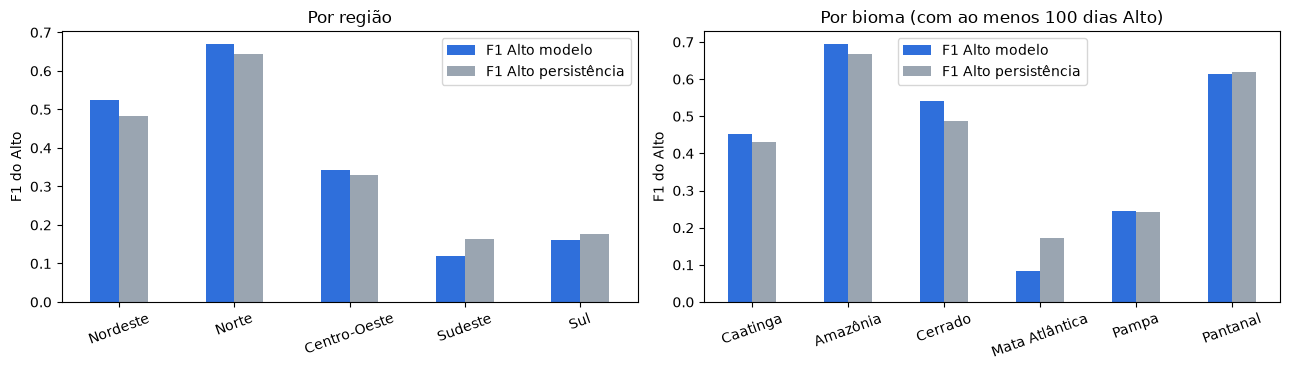

In [16]:
fig, eixos = plt.subplots(1, 2, figsize=(13, 3.8))
for eixo, tabela, titulo in [(eixos[0], vies_regiao, 'Por região'), (eixos[1], vies_bioma[vies_bioma['dias Alto'] >= 100], 'Por bioma (com ao menos 100 dias Alto)')]:
    tabela[['F1 Alto modelo', 'F1 Alto persistência']].plot(kind='bar', rot=20, color=[AZUL, CINZA], ax=eixo)
    eixo.set_title(titulo)
    eixo.set_xlabel('')
    eixo.set_ylabel('F1 do Alto')
plt.tight_layout()
plt.show()

**Há viés por região, e ele é grande.** No período de teste, o modelo avisa 74 de cada 100 dias Alto no Norte e 48 no
Nordeste, mas só 28 no Centro-Oeste, 11 no Sul e 7 no Sudeste. Em bioma, o retrato é o mesmo: 75 na Amazônia e 5 na
Mata Atlântica. No Sudeste, no Sul e na Mata Atlântica, o F1 do Alto do modelo fica abaixo do da persistência
(0,1196 contra 0,1623 no Sudeste e 0,0830 contra 0,1722 na Mata Atlântica). E Sudeste, Sul e Centro-Oeste têm recall abaixo do
da persistência.

**A causa provável é a época do ano e a falta de exemplos, e não uma falha de conta.** De novembro a fevereiro, é época de chuva em boa
parte dessas regiões: o Sudeste tem só 1 132 dias Alto no teste, contra 19 418 do Nordeste. Em outubro, ainda seco em boa parte do
país, o recall sobe de 7 para 46 no Sudeste e de 28 para 72 no Centro-Oeste, e o modelo supera a persistência no F1 do Alto
nas cinco regiões. O Sul é diferente: o recall fica baixo nos dois períodos (11 no teste e 11 em outubro), com poucos dias
Alto para aprender (336 em outubro). Mesmo com a causa explicada, o efeito é real: um município do Sudeste com fogo fora de
época recebe aviso muito menos vezes que um do Norte.

**O que fazer com isso:**
- no uso real, não trocar a prática local pelo modelo nas regiões Sudeste e Sul; nelas, o modelo entra só como apoio,
  e a régua "hoje = ontem" deve valer junto;
- acompanhar o recall por região todo mês, com um alerta se alguma região cair;
- no teste A/B (Etapa 2), usar os pares formados dentro de cada região para medir o efeito região por região;
- com mais anos de dados, treinar com mais de uma estação seca de cada região.

**Distância até a estação:** os 128 municípios cuja estação fica, em geral, a mais de 150 km não vão pior que os demais
(recall de 60 e F1 do Alto de 0,5760), e os três grupos superam a persistência. Eles são poucos e têm muito fogo, e o histórico
de focos diz muito sobre eles. Por isso, não há sinal de prejuízo para quem tem a estação longe, mas essa comparação não mede
o valor do clima.

## 6. Boletim em texto

O enunciado traz, como opcional, um texto automático gerado com ajuda de um modelo de linguagem (LLM). Este projeto
gera o boletim **com regra fixa**, sem LLM: uma frase padrão preenchida com o nível previsto e com os 3 fatores que
mais pesaram segundo o SHAP. A escolha é deliberada:
- todo número do texto vem direto da base, e nada é inventado;
- o repositório é público, e a regra fixa não precisa de chave de acesso a serviço pago;
- qualquer pessoa reproduz o resultado exato, sem internet.

O boletim não mostra porcentagem, de propósito: como o modelo dá peso maior aos níveis raros, a "probabilidade" dele
serve para ordenar os dias, e não é uma chance real de fogo.

O exemplo usa o dia do teste com mais avisos Alto. Cada linha mostra, entre colchetes, o que de fato aconteceu: o boletim erra às vezes, como o modelo.

In [17]:
NOMES_LEGIVEIS = {
    'focos_ontem': ('focos ontem', '{:.0f}'), 'focos_7d': ('focos nos últimos 7 dias', '{:.0f}'),
    'focos_30d': ('focos nos últimos 30 dias', '{:.0f}'), 'dias_com_foco_30d': ('dias com foco nos últimos 30', '{:.0f}'),
    'umidade_min_ontem': ('umidade mínima de ontem', '{:.0f}%'), 'temp_max_ontem': ('temperatura máxima de ontem', '{:.0f} °C'),
    'chuva_ontem': ('chuva de ontem', '{:.1f} mm'), 'chuva_7d': ('chuva nos últimos 7 dias', '{:.1f} mm'),
    'vento_ontem': ('vento de ontem', '{:.1f} m/s'), 'distancia_estacao_km': ('distância até a estação', '{:.0f} km'),
    'area_km2': ('área do município', '{:.0f} km²'),
    'pct_floresta': ('floresta no município', '{:.0f}%'), 'pct_natural_nao_florestal': ('vegetação natural não florestal', '{:.0f}%'),
    'pct_pastagem': ('pastagem no município', '{:.0f}%'), 'pct_agricultura': ('agricultura no município', '{:.0f}%'),
    'pct_mosaico': ('mosaico de usos no município', '{:.0f}%'), 'pct_nao_vegetada': ('área não vegetada', '{:.0f}%'),
    'pct_agua': ('água no município', '{:.0f}%'), 'perda_nativa_5a': ('perda de vegetação nativa em 5 anos', '{:.1f}% da área'),
    'sigla_uf': ('estado', '{}'),
}
ORIENTACAO = {'Alto': 'Manter equipe de prontidão.', 'Médio': 'Manter atenção e equipe de sobreaviso.', 'Baixo': 'Sem necessidade de prontidão.'}
nomes_municipios = pd.read_csv(RAIZ / 'dados' / 'externos' / 'municipios.csv').set_index('codigo_ibge')['nome']

def valor_legivel(coluna, valor):
    if pd.isna(valor):
        return 'sem dado'
    if coluna.startswith('pct_') or coluna == 'perda_nativa_5a':  # na base, essas colunas são proporções de 0 a 1
        valor = valor * 100
    return NOMES_LEGIVEIS[coluna][1].format(valor).replace('.', ',')

def boletim(linha, shap_da_linha, nivel):
    # Os 3 fatores que mais empurraram para o nível previsto.
    fatores = pd.Series(shap_da_linha, index=pm.FEATURES).sort_values(ascending=False).head(3).index
    texto = '; '.join(f'{NOMES_LEGIVEIS[c][0]}: {valor_legivel(c, linha[c])}' for c in fatores)
    nome = nomes_municipios.get(int(linha['id_municipio']), 'Município')
    return f"{nome} ({linha['sigla_uf']}), {linha['dia']:%d/%m/%Y}: risco {nivel.upper()}. O que mais pesou: {texto}. {ORIENTACAO[nivel]}"

teste_prev = teste.assign(previsto=prev_final_te)
dia_exemplo = teste_prev[teste_prev['previsto'] == 'Alto']['dia'].value_counts().idxmax()
do_dia = teste_prev[teste_prev['dia'] == dia_exemplo]
exemplos = pd.concat([do_dia[do_dia['previsto'] == nivel].sort_values('focos_7d', ascending=False).head(2) for nivel in ['Alto', 'Médio', 'Baixo']])
valores_ex = valores_shap(exemplos)
textos = [boletim(linha, valores_ex[i, :, classes.index(linha['previsto'])], linha['previsto'])
          for i, (_, linha) in enumerate(exemplos.iterrows())]
pd.DataFrame({'id_municipio': exemplos['id_municipio'].values, 'dia': exemplos['dia'].dt.date.values, 'real': exemplos['nivel_risco'].astype(str).values,
              'previsto': exemplos['previsto'].values, 'boletim': textos}).to_csv(RESULTADOS / 'boletim_exemplo.csv', index=False)
print(f'Dia do exemplo: {dia_exemplo:%d/%m/%Y}\n')
for texto, real in zip(textos, exemplos['nivel_risco'].astype(str)):
    print(texto, f'[real: {real}]\n')

Dia do exemplo: 02/11/2024

Portel (PA), 02/11/2024: risco ALTO. O que mais pesou: focos ontem: 1073; focos nos últimos 30 dias: 16163; focos nos últimos 7 dias: 5752. Manter equipe de prontidão. [real: Alto]

Moju (PA), 02/11/2024: risco ALTO. O que mais pesou: focos ontem: 1432; focos nos últimos 30 dias: 10041; focos nos últimos 7 dias: 4426. Manter equipe de prontidão. [real: Alto]

Palmas de Monte Alto (BA), 02/11/2024: risco MÉDIO. O que mais pesou: dias com foco nos últimos 30: 22; área do município: 2560 km²; estado: BA. Manter atenção e equipe de sobreaviso. [real: Alto]

Itapetinga (BA), 02/11/2024: risco MÉDIO. O que mais pesou: dias com foco nos últimos 30: 16; estado: BA; área do município: 1651 km². Manter atenção e equipe de sobreaviso. [real: Baixo]

Carinhanha (BA), 02/11/2024: risco BAIXO. O que mais pesou: chuva nos últimos 7 dias: 44,2 mm; focos ontem: 0; distância até a estação: 69 km. Sem necessidade de prontidão. [real: Médio]

Santa Maria das Barreiras (PA), 02/

## 7. Conclusão do projeto: a hipótese se confirma?

**Hipótese:** com o que se sabe até a véspera, um modelo avisa os dias de risco Alto melhor do que a regra "hoje = ontem"
e reduz o custo de posicionar equipes.

**Resposta: confirmada em parte.** O modelo final, a regressão logística com corte único, é melhor que a régua e custa
menos, mas não atinge a meta de dias Alto avisados, que é a mais importante para quem precisa chegar a tempo.

| Meta | Persistência | Modelo final | Atingida? |
|---|---|---|---|
| Acerto geral (F1 macro) de pelo menos 0,55 | 0,5490 | 0,5709 | **sim** |
| Pelo menos 55 de cada 100 avisos Alto certos | 49,2 | 57,6 | **sim** |
| Pelo menos 60 de cada 100 dias Alto avisados | 49,8 | 51,2 | **não** (faltam 8,8 pontos) |
| Custo menor que o da persistência | R$ 434,8 milhões | R$ 420,1 milhões | **sim**, R$ 14,7 milhões a menos |

**O que isso significa para quem decide:**
1. **Vale usar o modelo como lista diária de prioridade,** principalmente nos meses de mais fogo e no Norte e no
   Nordeste, onde ele é mais forte. Ele avisa um pouco mais de dias Alto e erra menos avisos que a régua mínima, supera a
   persistência nas 3 faixas maiores de município e vale em municípios que nunca viu (Etapa 2, seção 6.2).
2. **Ele não substitui a prática das equipes.** A comparação foi com uma referência estatística mínima. A régua
   ideal, a previsão de risco do Instituto Nacional de Pesquisas Espaciais (INPE), não pôde ser medida, porque na base
   ela só existe quando já há fogo.
3. **O gestor escolhe o corte.** Mais avisos custam mais prontidão, e menos avisos deixam mais fogo sem equipe. A
   seção 7.2 da Etapa 2 mostra o preço de cada opção.
4. **Sudeste, Sul e municípios pequenos exigem cuidado,** pelo viés da seção 5 e pelas faixas de tamanho.
5. **A economia em reais é uma estimativa.** Depende da premissa dos 5 hectares, e só o teste A/B planejado na Etapa 2
   pode comprovar o ganho.

**Principais limitações:** um só ano de dados, com uma única estação seca no treino e nenhum dia de outubro a dezembro
(por isso o calendário saiu do modelo); uso do solo de 2021; clima vindo da estação mais próxima; o alvo mede o fogo
visto por satélite e conta focos sem dividir pela área.

**Próximos passos:** treinar com mais anos, testar o risco em focos por km² e rodar o teste A/B numa estação seca.